In [1]:
import sys
import pandas

print(sys.executable)
print(pandas.__version__)

ModuleNotFoundError: No module named 'pandas'

In [1]:
import sys
import pandas

print(sys.executable)
print(pandas.__version__)

/Users/isha/Desktop/freight-forecasting-system/ml/venv/bin/python
3.0.5


In [2]:
import pandas as pd

file_path = "../data/processed/freight_forecasting_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (180, 18)

Columns:
['Date', 'Freight_Index', 'India_Dry_Cargo_Loaded', 'India_Dry_Cargo_Discharged', 'Chennai_Total_Traffic', 'Kamarajar_Total_Traffic', 'Paradip_Total_Traffic', 'SMP_Kolkata_Haldia_Total_Traffic', 'Visakhapatnam_Total_Traffic', 'Aluminum', 'Coal, Australian', 'Coal, South African **', 'Copper', 'Crude oil, Brent', 'Iron ore, cfr spot', 'Natural gas, Europe', 'Soybeans', 'Wheat, US HRW']


In [3]:
# Basic dataset inspection

print("DATASET INFORMATION")
print("=" * 50)

print("\nShape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDate Range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

DATASET INFORMATION

Shape: (180, 18)

Data Types:
Date                                    str
Freight_Index                         int64
India_Dry_Cargo_Loaded              float64
India_Dry_Cargo_Discharged          float64
Chennai_Total_Traffic               float64
Kamarajar_Total_Traffic             float64
Paradip_Total_Traffic               float64
SMP_Kolkata_Haldia_Total_Traffic    float64
Visakhapatnam_Total_Traffic         float64
Aluminum                            float64
Coal, Australian                    float64
Coal, South African **              float64
Copper                              float64
Crude oil, Brent                    float64
Iron ore, cfr spot                  float64
Natural gas, Europe                 float64
Soybeans                            float64
Wheat, US HRW                       float64
dtype: object

Missing Values:
Date                                 0
Freight_Index                        0
India_Dry_Cargo_Loaded               0
India_Dry

In [4]:
# Convert Date column to datetime

df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].dtype)
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

datetime64[us]
Start: 2011-01-01 00:00:00
End: 2025-12-01 00:00:00


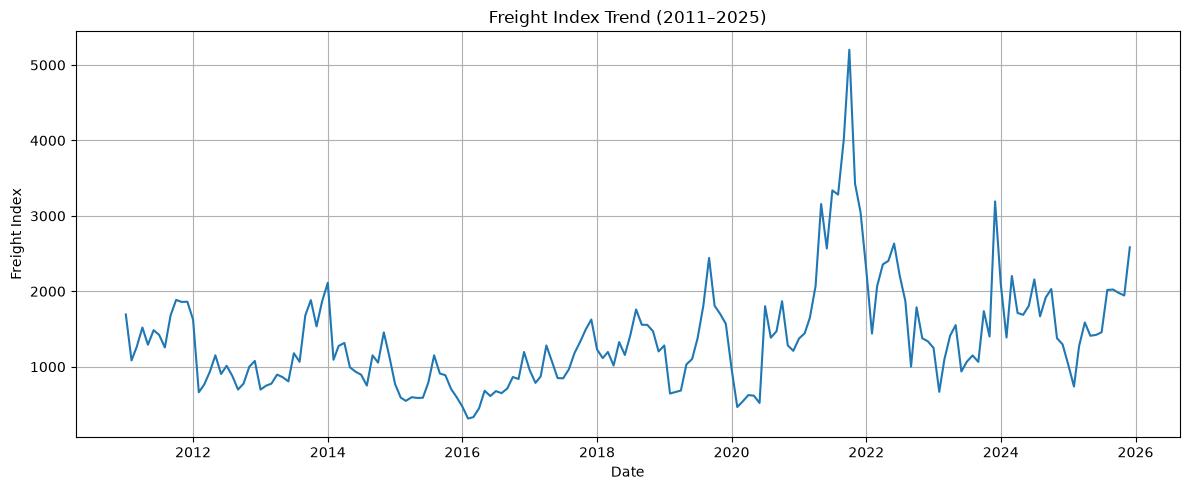

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Freight_Index"])

plt.title("Freight Index Trend (2011–2025)")
plt.xlabel("Date")
plt.ylabel("Freight Index")

plt.grid(True)
plt.tight_layout()
plt.show()

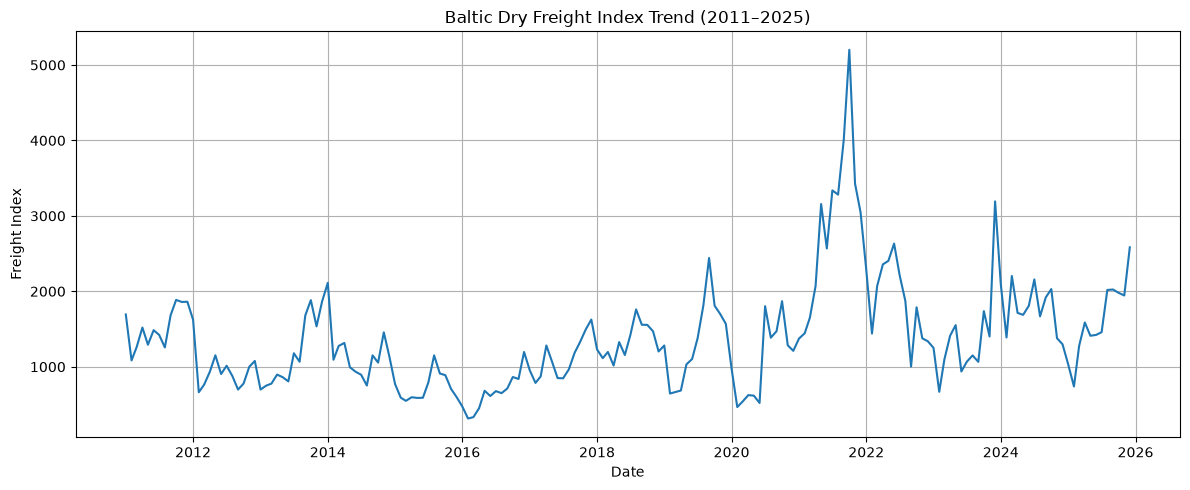

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Freight_Index"])

plt.title("Baltic Dry Freight Index Trend (2011–2025)")
plt.xlabel("Date")
plt.ylabel("Freight Index")

plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Freight Index Statistical Summary

print("FREIGHT INDEX STATISTICS")
print("=" * 40)

print("Mean:", df["Freight_Index"].mean())
print("Median:", df["Freight_Index"].median())
print("Minimum:", df["Freight_Index"].min())
print("Maximum:", df["Freight_Index"].max())
print("Standard Deviation:", df["Freight_Index"].std())

FREIGHT INDEX STATISTICS
Mean: 1374.0666666666666
Median: 1269.0
Minimum: 314
Maximum: 5202
Standard Deviation: 705.5638388737457


In [8]:
# Calculate monthly freight-index change

df["Freight_Change"] = df["Freight_Index"].pct_change() * 100

print("Freight volatility statistics")
print("=" * 40)

print("Average monthly change:",
      df["Freight_Change"].mean())

print("Maximum monthly increase:",
      df["Freight_Change"].max())

print("Maximum monthly decrease:",
      df["Freight_Change"].min())

Freight volatility statistics
Average monthly change: 4.485134136829788
Maximum monthly increase: 246.73076923076925
Maximum monthly decrease: -59.23645320197044


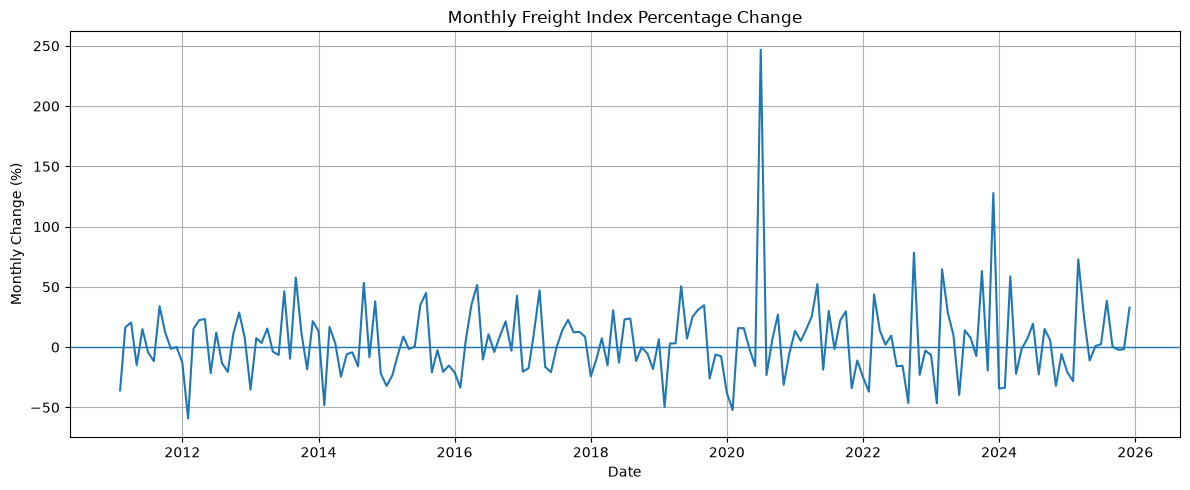

In [9]:
# Monthly Freight Index Volatility

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Freight_Change"])

plt.axhline(0, linewidth=1)

plt.title("Monthly Freight Index Percentage Change")
plt.xlabel("Date")
plt.ylabel("Monthly Change (%)")

plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
top_increases = df.nlargest(5, "Freight_Change")[
    ["Date", "Freight_Index", "Freight_Change"]
]

top_decreases = df.nsmallest(5, "Freight_Change")[
    ["Date", "Freight_Index", "Freight_Change"]
]

print("Largest Monthly Increases")
print("=" * 50)
display(top_increases)

print("\nLargest Monthly Decreases")
print("=" * 50)
display(top_decreases)

Largest Monthly Increases


,Date,Freight_Index,Freight_Change
114,2020-07-01,1803,246.730769
155,2023-12-01,3192,127.837259
141,2022-10-01,1788,78.443114
170,2025-03-01,1276,72.899729
146,2023-03-01,1099,64.520958



Largest Monthly Decreases


,Date,Freight_Index,Freight_Change
13,2012-02-01,662,-59.236453
109,2020-02-01,466,-52.254098
97,2019-02-01,645,-49.687988
37,2014-02-01,1093,-48.272598
145,2023-02-01,668,-46.560000


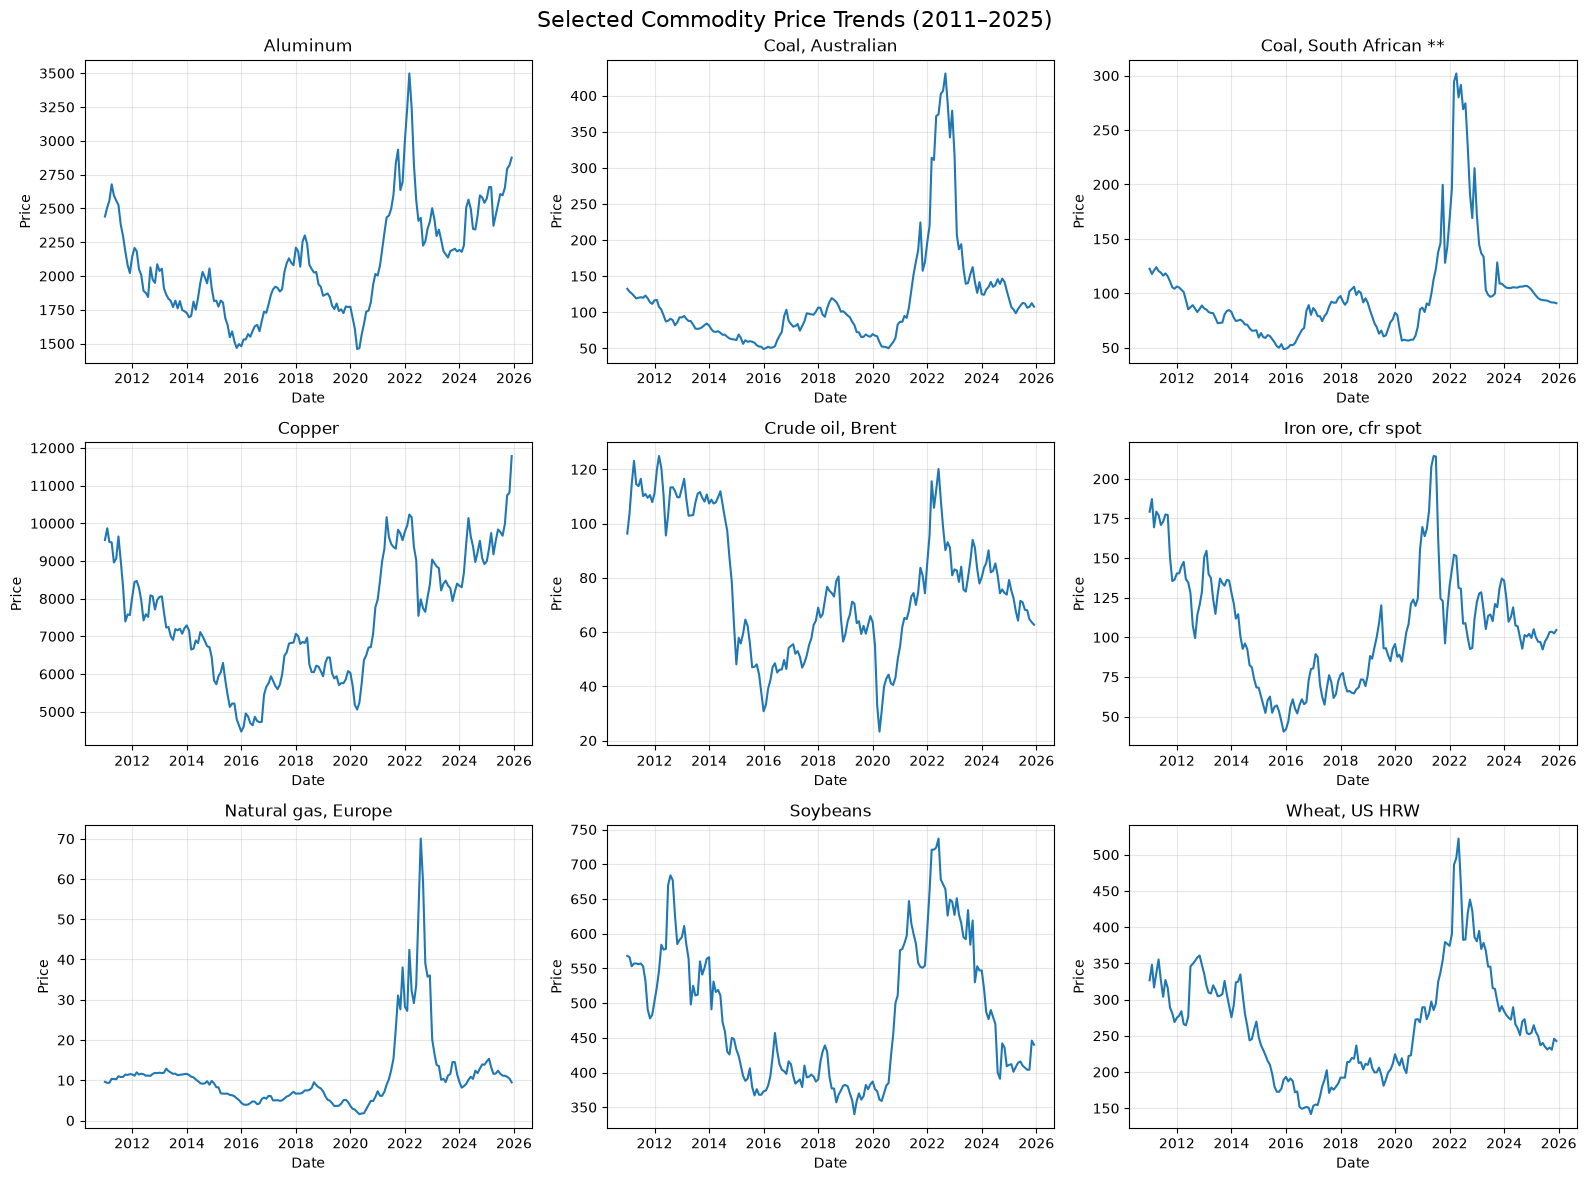

In [11]:
commodity_cols = [
    "Aluminum",
    "Coal, Australian",
    "Coal, South African **",
    "Copper",
    "Crude oil, Brent",
    "Iron ore, cfr spot",
    "Natural gas, Europe",
    "Soybeans",
    "Wheat, US HRW"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, col in zip(axes.flat, commodity_cols):
    ax.plot(df["Date"], df[col])
    ax.set_title(col)
    ax.set_xlabel("Date")
    ax.set_ylabel("Price")
    ax.grid(True, alpha=0.3)

plt.suptitle("Selected Commodity Price Trends (2011–2025)", fontsize=16)
plt.tight_layout()
plt.show()

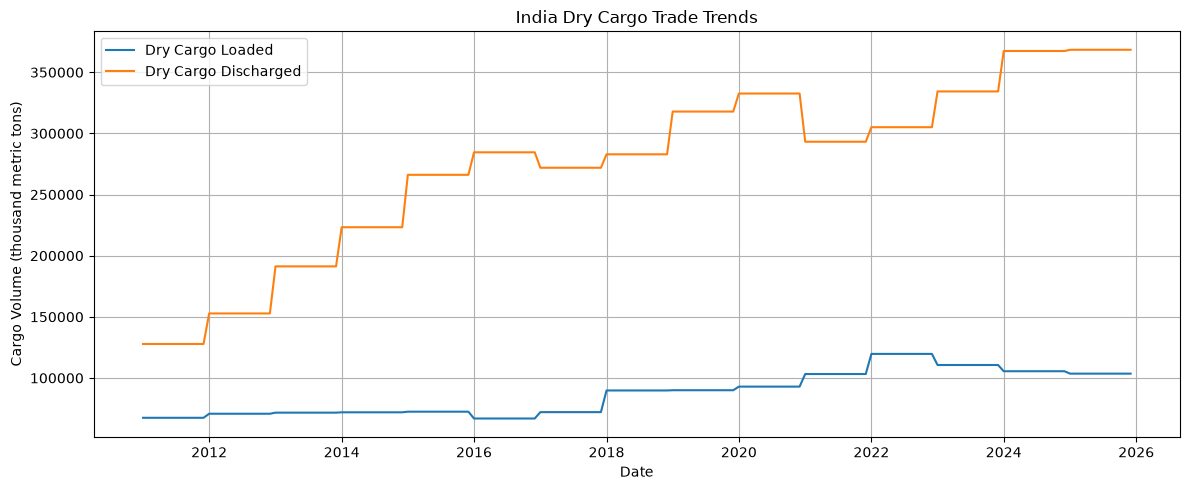

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["India_Dry_Cargo_Loaded"],
    label="Dry Cargo Loaded"
)

plt.plot(
    df["Date"],
    df["India_Dry_Cargo_Discharged"],
    label="Dry Cargo Discharged"
)

plt.title("India Dry Cargo Trade Trends")
plt.xlabel("Date")
plt.ylabel("Cargo Volume (thousand metric tons)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
print("TRADE DATA STATISTICS")
print("=" * 50)

print("\nDry Cargo Loaded:")
print("Mean:", df["India_Dry_Cargo_Loaded"].mean())
print("Minimum:", df["India_Dry_Cargo_Loaded"].min())
print("Maximum:", df["India_Dry_Cargo_Loaded"].max())

print("\nDry Cargo Discharged:")
print("Mean:", df["India_Dry_Cargo_Discharged"].mean())
print("Minimum:", df["India_Dry_Cargo_Discharged"].min())
print("Maximum:", df["India_Dry_Cargo_Discharged"].max())

TRADE DATA STATISTICS

Dry Cargo Loaded:
Mean: 87208.44333333334
Minimum: 66833.818
Maximum: 119667.368

Dry Cargo Discharged:
Mean: 274628.7113333333
Minimum: 127781.219
Maximum: 368404.571


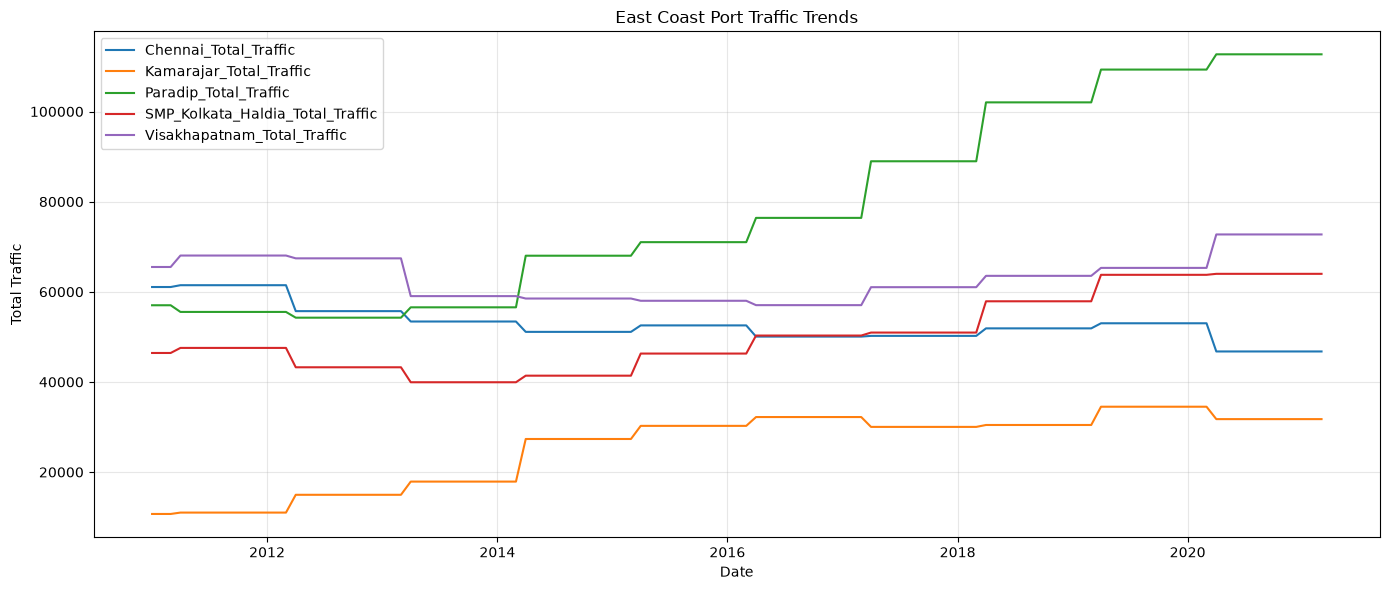

In [14]:
port_cols = [
    "Chennai_Total_Traffic",
    "Kamarajar_Total_Traffic",
    "Paradip_Total_Traffic",
    "SMP_Kolkata_Haldia_Total_Traffic",
    "Visakhapatnam_Total_Traffic"
]

plt.figure(figsize=(14, 6))

for col in port_cols:
    plt.plot(df["Date"], df[col], label=col)

plt.title("East Coast Port Traffic Trends")
plt.xlabel("Date")
plt.ylabel("Total Traffic")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
print("PORT TRAFFIC MISSING VALUES")
print("=" * 50)

for col in port_cols:
    print(col, ":", df[col].isna().sum())

PORT TRAFFIC MISSING VALUES
Chennai_Total_Traffic : 57
Kamarajar_Total_Traffic : 57
Paradip_Total_Traffic : 57
SMP_Kolkata_Haldia_Total_Traffic : 57
Visakhapatnam_Total_Traffic : 57


In [16]:
print("PORT TRAFFIC STATISTICS")
print("=" * 60)

for col in port_cols:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())

PORT TRAFFIC STATISTICS

 Chennai_Total_Traffic
Mean: 52820.0243902439
Minimum: 46758.0
Maximum: 61460.0

 Kamarajar_Total_Traffic
Mean: 25661.439024390245
Minimum: 10703.0
Maximum: 34498.0

 Paradip_Total_Traffic
Mean: 78924.75609756098
Minimum: 54254.0
Maximum: 112689.0

 SMP_Kolkata_Haldia_Total_Traffic
Mean: 50427.58536585366
Minimum: 39928.0
Maximum: 63983.0

 Visakhapatnam_Total_Traffic
Mean: 63121.68292682927
Minimum: 57035.0
Maximum: 72722.0


In [17]:
numeric_cols = df.select_dtypes(include="number").columns

correlation = df[numeric_cols].corr()["Freight_Index"].sort_values(
    ascending=False
)

print("CORRELATION WITH FREIGHT INDEX")
print("=" * 50)
print(correlation)

CORRELATION WITH FREIGHT INDEX
Freight_Index                       1.000000
Aluminum                            0.591351
Copper                              0.570729
India_Dry_Cargo_Loaded              0.487518
Coal, South African **              0.476336
Iron ore, cfr spot                  0.423401
Coal, Australian                    0.402979
Natural gas, Europe                 0.397462
Wheat, US HRW                       0.376087
Soybeans                            0.320292
Visakhapatnam_Total_Traffic         0.311808
Freight_Change                      0.268557
Crude oil, Brent                    0.191227
India_Dry_Cargo_Discharged          0.189578
SMP_Kolkata_Haldia_Total_Traffic    0.188795
Chennai_Total_Traffic               0.170439
Paradip_Total_Traffic               0.128292
Kamarajar_Total_Traffic            -0.175242
Name: Freight_Index, dtype: float64


## EDA Summary

The integrated freight forecasting dataset contains 180 monthly observations
from January 2011 to December 2025 and includes the Freight Index, trade
indicators, East Coast port traffic, and selected commodity prices.

The Freight Index shows considerable variation over the study period, with
values ranging from 314 to 5202. Monthly percentage changes also indicate
substantial volatility, with both sharp increases and decreases observed.

The selected commodity variables show varying relationships with the Freight
Index. Aluminum and Copper have the strongest positive correlations among the
selected commodity features.

India's dry cargo loaded and discharged volumes show substantial variation,
indicating changes in dry-bulk trade activity that may provide useful
supporting information for freight forecasting.

The selected East Coast ports also show variation in total traffic. Paradip
has the highest average traffic among the selected ports. However, port
traffic features contain missing values for periods where the source data is
not available. These values should not be interpreted as zero traffic.

Correlation analysis shows that Aluminum, Copper, India Dry Cargo Loaded,
South African Coal, and Iron Ore have relatively stronger positive
relationships with the Freight Index. However, correlation does not imply
causation, and feature usefulness will ultimately be evaluated using
time-aware forecasting models.

The current target is the Baltic Dry Freight Index, which represents a
global dry-bulk freight market indicator rather than a route-specific
East Coast India freight rate. Therefore, this limitation should be
considered when interpreting the forecasting results.